Dataset Loaded Successfully
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  

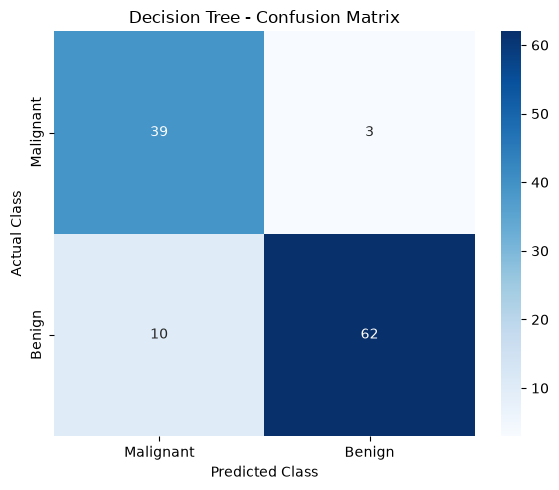

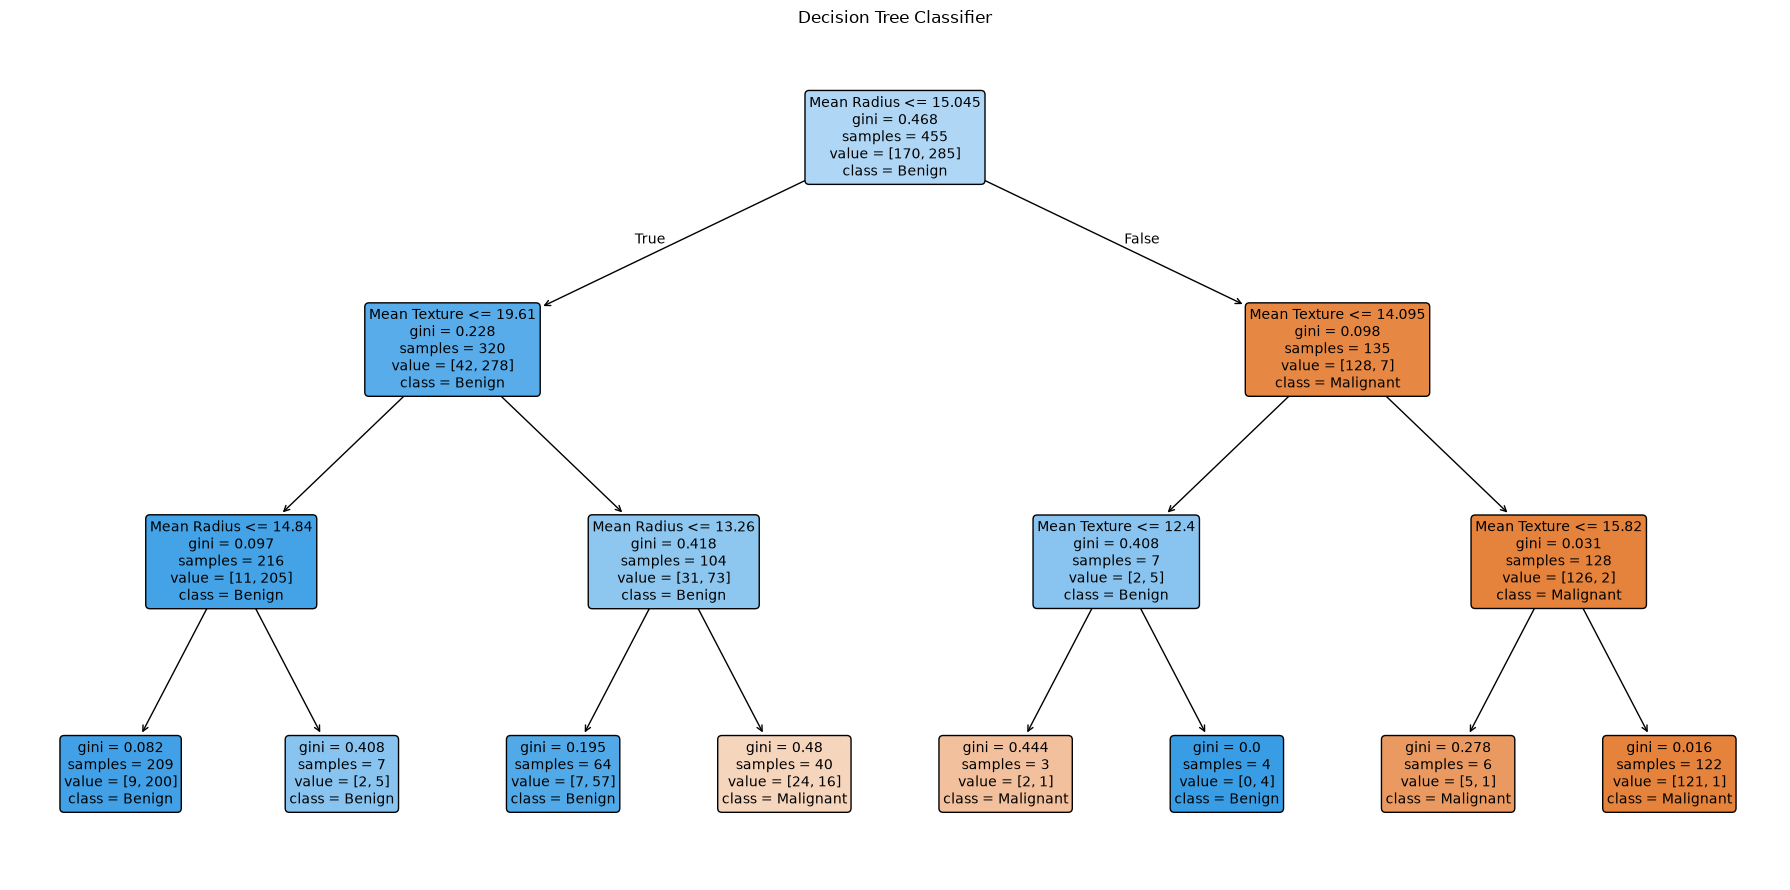

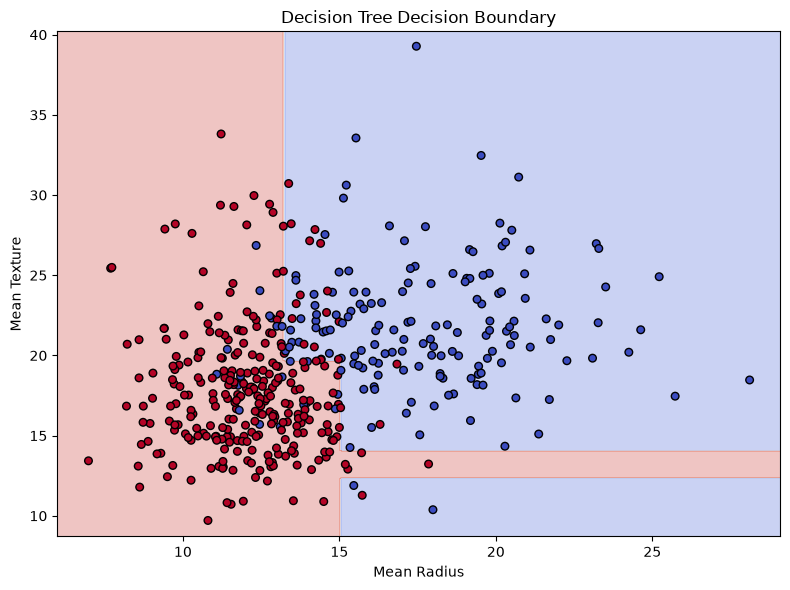

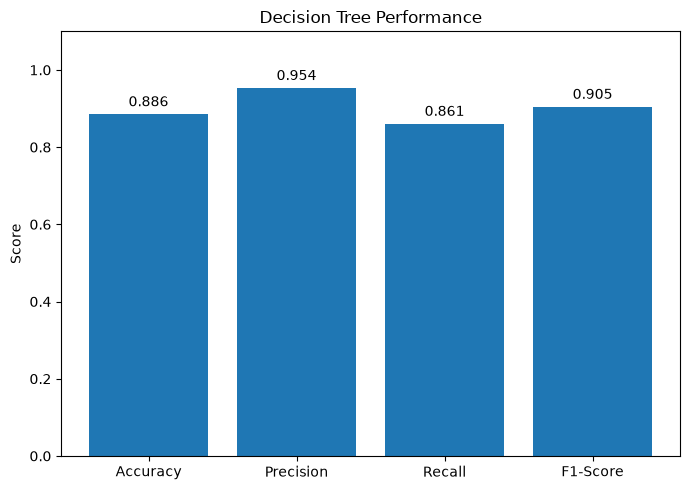


Decision Tree Classifier Completed Successfully!


In [2]:
# DAV LAB EXPERIMENT
# Decision Tree Classifier
# Building, Visualizing and Evaluating the Model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Import Dataset from Local CSV File
df = pd.read_csv("breast_cancer_dataset.csv")

print("Dataset Loaded Successfully")
print(df.head())

# 2. Select Input Features and Target
X = df[["mean radius", "mean texture"]]
y = df["target"]

feature_names = ["Mean Radius", "Mean Texture"]
class_names = ["Malignant", "Benign"]

# 3. Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Build Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

# 5. Make Predictions
y_pred = model.predict(X_test)

# 6. Evaluate Model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n----- MODEL EVALUATION -----")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualization 1: Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 8. Visualization 2: Decision Tree
plt.figure(figsize=(18, 9))

plot_tree(
    model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.show()

# 9. Visualization 3: Decision Boundary

# Create mesh grid
x_min, x_max = X["mean radius"].min() - 1, X["mean radius"].max() + 1
y_min, y_max = X["mean texture"].min() - 1, X["mean texture"].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1),
    np.arange(y_min, y_max, 0.1)
)

# Predict class for each grid point
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=["mean radius", "mean texture"]
)

Z = model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap="coolwarm"
)

plt.scatter(
    X_train["mean radius"],
    X_train["mean texture"],
    c=y_train,
    cmap="coolwarm",
    edgecolors="black",
    s=30
)

plt.title("Decision Tree Decision Boundary")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.tight_layout()
plt.show()

# 10. Visualization 4: Performance Metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(7, 5))

bars = plt.bar(metrics, values)

plt.ylim(0, 1.1)
plt.title("Decision Tree Performance")
plt.ylabel("Score")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# 11. Final Result
print("\nDecision Tree Classifier Completed Successfully!")
